# Title

## Imports

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.cm as cm
import random
from scipy.stats import norm
import pandas as pd
from mpl_toolkits.mplot3d import Axes3D

## Training and Test Data Splitter

In [48]:
# Training and Test Data Splitter
def train_test_split (df, i=0) :
    train = df.sample(frac=2/3, random_state=i)
    test = df.drop(train.index)
    xtrain = train.drop(columns=['MEDV'])
    xtest = test.drop(columns=['MEDV'])
    ytrain = train['MEDV']
    ytest = test['MEDV']
    return xtrain, xtest, ytrain, ytest


## Basis Functions

In [49]:
# Basis Functions
# Vector of ones ie constant basis
def ones_basis (x) :
    return np.ones((len(x), 1))

def single_attr_basis (x, att_col) :
    ones = np.ones((len(x), 1))
    att = np.asarray(x.iloc[:, att_col])
    att = att.reshape(-1, 1)
    return np.column_stack((ones, att))

def all_attr_basis (x) :
    noAtt = x.shape[1]
    theta = np.ones((len(x), 1))
    for i in range (noAtt) :
        theta = np.column_stack((theta, single_attr_basis(x,i)[:, 1:]))
    return theta

## Linear regression Solvers

In [50]:
# Linear Regression Functions
# Solves least squares equation, y = θw, returns weights w
def least_sqr_sol (theta, y) :
    # return np.linalg.inv(theta.T@theta)@theta.T@y
    w, *_ = np.linalg.lstsq(theta, y, rcond=None)
    return w


# Fits a single model degree and returns weights, predictions and MSE
def lin_reg_sol(x,y, basis_func = ones_basis, **kwargs) :
    # theta = poly_basis(x,k)
    theta = basis_func(x, **kwargs)
    # print('Theta = ')
    # print(theta)
    w = least_sqr_sol(theta,y)
    y_hat = theta @ w
    mse = np.mean((y - y_hat)**2)
    return [w, y_hat, mse]


# Runs r reps of model fitting, each with different train/test splits, returns the average MSE across runs (train and test)
def r_sims(df, r, basis_func=ones_basis, splits=None,  **kwargs) :
    results=[]
    for i in range(r):
        if splits is None :
            xtrain, xtest, ytrain, ytest = train_test_split(df, i)
        else :
            xtrain, xtest, ytrain, ytest = splits[i]
        lm = lin_reg_sol(xtrain, ytrain, basis_func, **kwargs)
        mse_train = lm[2]
        w = lm[0]
        theta_test = basis_func(xtest, **kwargs)
        y_hat_test = theta_test @ w
        mse_test = np.mean((ytest - y_hat_test) ** 2)
        mse = [mse_train, mse_test]
        results.append(mse)
    avgmse = [0,0]
    avgmse_sd = [0,0]

    for i in range(2):
        total = 0
        for j in range(r):
            total += results[j][i]
        avgmse[i] = total / r

    if r > 1 :
        for i in range(2):
            total = 0
            for j in range(r):
                total += (results[j][i]-avgmse[i])**2
            avgmse_sd[i] = total / (r-1)
            avgmse_sd[i] = avgmse_sd[i]**(1/2)
    else :
        avgmse_sd = [None,None]

    avgmse_df = pd.DataFrame({'avg_mse_train': [avgmse[0]], 'avg_mse_test': [avgmse[1]], 'avg_mse_train_sd': [avgmse_sd[0]], 'avg_mse_test_sd': [avgmse_sd[1]]})
    return avgmse_df, w


## Plotting Functions

In [51]:
# Plots
def plot_crossVal_mse(df):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    sig = sorted(df['sig'].unique())
    gam = sorted(df['gam'].unique())
    mse = np.zeros((len(gam), len(sig)))
    print(df['avg_mse_test_fold'])
    for i, g in enumerate(gam) :
        for j, s in enumerate(sig) :
            mse[i,j] = df.loc[(df['sig'] == s) & (df['gam']== g), 'avg_mse_test_fold'].values[0]

    s, g = np.meshgrid(sig, gam)
    ax.plot_surface(np.log2(s), np.log2(g), np.log(mse),
                    cmap='viridis', edgecolor='none', alpha=0.9)

    ax.set_xlabel('log₂(σ)')
    ax.set_ylabel('log₂(γ)')
    ax.set_zlabel('ln(MSE)')
    ax.set_title('Cross-validation error surface')
    ax.view_init(elev=30, azim=-30)
    return fig, ax

# Main Questions

## Question 4

### Load Data

In [37]:
print('Q4')
url = "http://www0.cs.ucl.ac.uk/staff/M.Herbster/boston-filter/Boston-filtered.csv"
df = pd.read_csv(url)
print(df.head())

Q4
      CRIM   ZN   INDUS   CHAS    NOX     RM   AGE     DIS  RAD  TAX  PTRATIO  \
0  0.00632  18.0    2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0    7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0    7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0    2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0    2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

   LSTAT  MEDV  
0   4.98  24.0  
1   9.14  21.6  
2   4.03  34.7  
3   2.94  33.4  
4   5.33  36.2  


### Q4.a - Naive Regression

In [38]:


print('Q4.a')
runs = 20
avgmse_df, w = r_sims(df, runs)
print('Naive Regression')
print(f"avg mse train {avgmse_df['avg_mse_train'][0]}, avg mse test {avgmse_df['avg_mse_test'][0]}, weight vector {w}")
print(' ')

Q4.a
Naive Regression
avg mse train 84.54296306210321, avg mse test 84.47043682903508, weight vector [22.05311573]
 


### Q4.c - Single attribute models

In [39]:
print('Q4.c')
runs = 20
for i in range(df.shape[1]-1):
    avgmse_df, w = r_sims(df, runs, basis_func=single_attr_basis, att_col=i)
    print(f'Linear Regression with single attribute {i} : {df.columns[i]}')
    print(f"avg mse train {avgmse_df['avg_mse_train'][0]}, avg mse test {avgmse_df['avg_mse_test'][0]}, weight vector {w}")
    print(' ')

Q4.c
Linear Regression with single attribute 0 : CRIM
avg mse train 71.24928461936693, avg mse test 73.91213710946536, weight vector [23.52535679 -0.39561527]
 
Linear Regression with single attribute 1 :  ZN 
avg mse train 74.1933902726768, avg mse test 72.3831005127153, weight vector [20.60518433  0.13330225]
 
Linear Regression with single attribute 2 : INDUS 
avg mse train 64.91553821103508, avg mse test 64.55971248350953, weight vector [29.24529451 -0.63268134]
 
Linear Regression with single attribute 3 : CHAS
avg mse train 82.01689163114625, avg mse test 82.19306104552274, weight vector [21.67381703  6.39118297]
 
Linear Regression with single attribute 4 : NOX
avg mse train 69.47586165627321, avg mse test 68.4828239833001, weight vector [ 40.3537352  -32.87779456]
 
Linear Regression with single attribute 5 : RM
avg mse train 43.35705959346741, avg mse test 44.46112005254263, weight vector [-33.10367008   8.86086152]
 
Linear Regression with single attribute 6 : AGE
avg mse tra

### Q4.d - All attributes

In [40]:
print('Q4.d')
runs = 20
print('Linear Regression with all attributes')
avgmse_df, w = r_sims(df, runs, basis_func=all_attr_basis)
print(f"avg mse train {avgmse_df['avg_mse_train'][0]}, avg mse test {avgmse_df['avg_mse_test'][0]}, weight vector {w}")
print(' ')

Q4.d
Linear Regression with all attributes
avg mse train 22.279920765123517, avg mse test 23.975248452710762, weight vector [ 4.24269207e+01 -1.21121654e-01  3.49903310e-02 -2.49488880e-02
  2.18353004e+00 -1.72510303e+01  3.60536515e+00  4.57301369e-03
 -1.48118721e+00  2.67915829e-01 -1.01430998e-02 -1.01672222e+00
 -5.55121332e-01]
 


## Question 5

## Kernel functions

In [41]:
def norm_p(x, p) :
    if p > 0 :
        x=np.asarray(x)
        return np.sum(np.abs(x)**p)**(1/p)
    else:
        return 'Norm not defined : p <= 0'

def guass_kern (x1, x2, sig) :
    diff = np.array(x1) - np.array(x2)
    num = norm_p(diff, 2)**2
    Kij = np.exp(-num/(2*(sig**2)))
    return Kij

## Full Kernel function

In [42]:
def full_kern (x1, kernel_func, sig, x2=None,) :
    x1 = np.asarray(x1)
    n1 =len(x1)
    if x2 is None :
        x2 = x1
        n2 = n1
    else:
        x2 = np.asarray(x2)
        n2 = len(x2)
    K = np.zeros((n1,n2))
    for i in range(n1) :
        for j in range(n2) :
            K[i,j] = kernel_func(x1[i], x2[j], sig)
    return K

## Kernel Ridge Regression Solvers + Cross validation functions

In [43]:
# Solves least squares equation, y = θw, returns weights w
def ker_ridg_sol (K, gamma, y) :
    l = len(y)
    # return np.linalg.inv(theta.T@theta)@theta.T@y
    alpha = np.linalg.solve((K+(gamma*l*np.identity(l))), y)
    return alpha

def ker_reg_sol(x,y, kernel_func, sig, gam) :
    # theta = poly_basis(x,k)
    K = full_kern(x, kernel_func=kernel_func, sig=sig)
    # K = kernel_func(x, **kwargs)
    # print('Theta = ')
    # print(theta)
    alpha = ker_ridg_sol(K, gam, y)
    y_hat = K @ alpha
    mse = np.mean((y - y_hat)**2)
    return [alpha, y_hat, mse]

def cross_validation(xtrain, ytrain, folds, kernel_func, siglist, gamlist):
    positions = np.arange(len(xtrain))
    np.random.shuffle(positions)
    foldPositions = np.array_split(positions, folds)
    x, y = [], []
    for i in foldPositions:
        x.append(xtrain.iloc[i])
        y.append(ytrain.iloc[i])


    K_precal = {sig: full_kern(xtrain, kernel_func=kernel_func, sig=sig) for sig in siglist}


    paraMatrix = []

    for i in siglist:
        for j in gamlist:
            paraMatrix.append([i, j])
    cross_results = []

    for sig, gam in paraMatrix:
        K_full = K_precal[sig]
        results = []

        for i in range(folds):

            xtrain_fold = np.concatenate([foldPositions[j] for j in range(folds) if j != i])
            xtest_fold = foldPositions[i]


            K_train = K_full[np.ix_(xtrain_fold, xtrain_fold)]
            K_test = K_full[np.ix_(xtest_fold, xtrain_fold)]
            ytrain_fold = ytrain.iloc[xtrain_fold]
            ytest_fold = ytrain.iloc[xtest_fold]


            alpha = ker_ridg_sol(K_train, gam, ytrain_fold)
            y_hat_train = K_train @ alpha
            y_hat_test = K_test @ alpha
            mse_train_fold = np.mean((ytrain_fold - y_hat_train) ** 2)
            mse_test_fold = np.mean((ytest_fold - y_hat_test) ** 2)
            mse = [mse_train_fold, mse_test_fold]
            results.append(mse)
        avgmse = [0, 0]

        for i in range(2):
            total = 0
            for j in range(folds):
                total += results[j][i]
            avgmse[i] = total / folds

        avgmse_df = pd.DataFrame({'sig': [sig], 'gam' : [gam], 'avg_mse_train_fold': [avgmse[0]], 'avg_mse_test_fold': [avgmse[1]]})
        cross_results.append(avgmse_df)
    cross_results = pd.concat(cross_results)
    cross_results = cross_results.sort_values(by ='avg_mse_test_fold', ascending=True)
    min_mse = cross_results.iloc[0]
    return float(min_mse['sig']), float(min_mse['gam']), min_mse['avg_mse_train_fold'], min_mse['avg_mse_test_fold'], cross_results

# Runs r reps of model fitting, each with different train/test splits, returns the average MSE across runs (train and test)
def r_sims_ker_reg_sol(df, r, kernel_func, sig, gam, splits=None, plot=False, **kwargs) :
    results=[]
    fig, ax = None, None
    for i in range(r):
        if splits is None:
            xtrain, xtest, ytrain, ytest = train_test_split(df, i)
        else:
            xtrain, xtest, ytrain, ytest = splits[i]
        minsig, mingam, _, _, crossValdf= cross_validation(xtrain, ytrain, 5, kernel_func, sig, gam)

        krm = ker_reg_sol(xtrain, ytrain, kernel_func, sig=minsig, gam=mingam)
        mse_train = krm[2]
        alpha = krm[0]
        K_test = full_kern(xtest, kernel_func=kernel_func, sig=minsig, x2=xtrain)
        y_hat_test = K_test @ alpha
        mse_test = np.mean((ytest - y_hat_test) ** 2)
        mse = [mse_train, mse_test]
        results.append(mse)
        print(f'For r = {i+1}, minsig = 2**{np.log2(minsig)}, mingam = 2**{np.log2(mingam)}, mse_train = {mse_train}, mse_test = {mse_test}')
    avgmse = [0,0]
    avgmse_sd = [0,0]

    for i in range(2):
        total = 0
        for j in range(r):
            total += results[j][i]
        avgmse[i] = total / r

    if r > 1 :
        for i in range(2):
            total = 0
            for j in range(r):
                total += (results[j][i]-avgmse[i])**2
            avgmse_sd[i] = total / (r-1)
            avgmse_sd[i] = avgmse_sd[i]**(1/2)
    else :
        avgmse_sd = [None,None]


    avgmse_df = pd.DataFrame({'avg_mse_train': [avgmse[0]], 'avg_mse_test': [avgmse[1]], 'avg_mse_train_sd': [avgmse_sd[0]], 'avg_mse_test_sd': [avgmse_sd[1]]})

    if plot == True and r>0:
        fig, ax = plot_crossVal_mse(crossValdf)
        plt.show()
        return avgmse_df, alpha, fig, ax
    else:
        return avgmse_df, alpha

### Q5.a

For r = 1, minsig = 2**8.5, mingam = 2**-26.0, mse_train = 9.110878972468845, mse_test = 10.077684365800122
0      14.685725
0      14.993875
0      15.192958
0      15.317499
0      15.389940
        ...     
0    3789.320665
0    4731.288918
0    6390.753218
0    7535.887034
0    9627.828523
Name: avg_mse_test_fold, Length: 195, dtype: float64


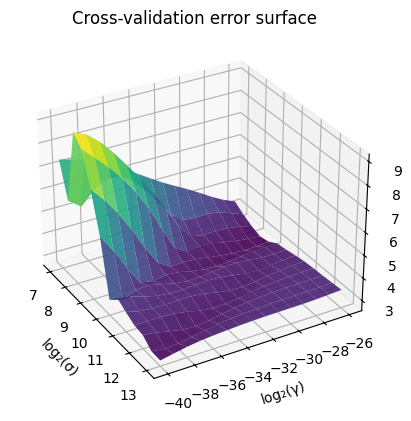

   avg_mse_train  avg_mse_test avg_mse_train_sd avg_mse_test_sd
0       9.110879     10.077684             None            None


In [44]:
gamma = [2**(-i) for i in range(40, 25, -1)]
sigma = [2**(7+(0.5*i)) for i in range(13)]

avgmse_df, alpha, fig, ax,  = r_sims_ker_reg_sol(df, 1, kernel_func=guass_kern, sig=sigma, gam=gamma, plot=True)
print(avgmse_df)

### Q5.b
As above
### Q5.c
As above

### Q5.d Summary table

In [52]:
print('Q5.d')
mse_table = pd.DataFrame(columns=['Method', 'MSE train', 'MSE test'])

runs = 20
rsplits = []
for i in range(runs):
    rsplits.append(train_test_split(df, i))

# 4.a
avgmse_df, w = r_sims(df, runs, splits=rsplits)
print('Naive Regression')
print(f"avg mse train {avgmse_df['avg_mse_train'][0]}±{avgmse_df['avg_mse_train_sd'][0]}, avg mse test {avgmse_df['avg_mse_test'][0]}±{avgmse_df['avg_mse_test_sd'][0]}")
print(' ')
mse_table.loc[len(mse_table)] = {'Method' : 'Naive Regression', 'MSE train' : f"{avgmse_df['avg_mse_train'][0]}±{avgmse_df['avg_mse_train_sd'][0]}", 'MSE test' : f"{avgmse_df['avg_mse_test'][0]}±{avgmse_df['avg_mse_test_sd'][0]}"}

 # 4.c
for i in range(df.shape[1]-1):
    avgmse_df, w = r_sims(df, runs, basis_func=single_attr_basis, splits= rsplits, att_col=i)
    print(f'Linear Regression with single attribute {i} : {df.columns[i]}')
    print(f"avg mse train {avgmse_df['avg_mse_train'][0]}±{avgmse_df['avg_mse_train_sd'][0]}, avg mse test {avgmse_df['avg_mse_test'][0]}±{avgmse_df['avg_mse_test_sd'][0]}")
    print(' ')
    mse_table.loc[len(mse_table)] = {'Method': f'Linear Regression (attribute {i})', 'MSE train': f"{avgmse_df['avg_mse_train'][0]}±{avgmse_df['avg_mse_train_sd'][0]}", 'MSE test': f"{avgmse_df['avg_mse_test'][0]}±{avgmse_df['avg_mse_test_sd'][0]}"}

# 4.d
print('Linear Regression with all attributes')
avgmse_df, w = r_sims(df, runs, basis_func=all_attr_basis, splits= rsplits)
print(f"avg mse train {avgmse_df['avg_mse_train'][0]}±{avgmse_df['avg_mse_train_sd'][0]}, avg mse test {avgmse_df['avg_mse_test'][0]}±{avgmse_df['avg_mse_test_sd'][0]}")
print(' ')
mse_table.loc[len(mse_table)] = {'Method': 'Linear Regression (all attributes)', 'MSE train': f"{avgmse_df['avg_mse_train'][0]}±{avgmse_df['avg_mse_train_sd'][0]}", 'MSE test': f"{avgmse_df['avg_mse_test'][0]}±{avgmse_df['avg_mse_test_sd'][0]}"}


# 5.a,c
gamma = [2**(-i) for i in range(40, 25, -1)]
sigma = [2**(7+(0.5*i)) for i in range(13)]
print('Kernel Ridge Regression')
avgmse_df, alpha = r_sims_ker_reg_sol(df, runs, kernel_func=guass_kern, sig=sigma, gam=gamma, splits=rsplits)
print(avgmse_df)
mse_table.loc[len(mse_table)] = {'Method': 'Kernel Ridge Regression', 'MSE train': f"{avgmse_df['avg_mse_train'][0]}±{avgmse_df['avg_mse_train_sd'][0]}", 'MSE test': f"{avgmse_df['avg_mse_test'][0]}±{avgmse_df['avg_mse_test_sd'][0]}"}


Q5.d
Naive Regression
avg mse train 84.54296306210321±5.528999666563973, avg mse test 84.47043682903508±11.03504107965914
 
Linear Regression with single attribute 0 : CRIM
avg mse train 71.24928461936693±5.02150773909797, avg mse test 73.91213710946536±10.670439713387081
 
Linear Regression with single attribute 1 :  ZN 
avg mse train 74.1933902726768±4.4562826578868675, avg mse test 72.3831005127153±8.99867464010775
 
Linear Regression with single attribute 2 : INDUS 
avg mse train 64.91553821103508±4.459446592689361, avg mse test 64.55971248350953±9.080223027741374
 
Linear Regression with single attribute 3 : CHAS
avg mse train 82.01689163114625±5.255390303356565, avg mse test 82.19306104552274±10.898412327526456
 
Linear Regression with single attribute 4 : NOX
avg mse train 69.47586165627321±4.560529169566954, avg mse test 68.4828239833001±9.209771831568405
 
Linear Regression with single attribute 5 : RM
avg mse train 43.35705959346741±3.0957879198072513, avg mse test 44.4611200

Summary output table

In [46]:
print (mse_table)

                                Method                             MSE train  \
0                     Naive Regression   84.54296306210321±5.528999666563973   
1      Linear Regression (attribute 0)    71.24928461936693±5.02150773909797   
2      Linear Regression (attribute 1)   74.1933902726768±4.4562826578868675   
3      Linear Regression (attribute 2)   64.91553821103508±4.459446592689361   
4      Linear Regression (attribute 3)   82.01689163114625±5.255390303356565   
5      Linear Regression (attribute 4)   69.47586165627321±4.560529169566954   
6      Linear Regression (attribute 5)  43.35705959346741±3.0957879198072513   
7      Linear Regression (attribute 6)    72.6851680752261±4.938381164192815   
8      Linear Regression (attribute 7)   79.43879565989793±5.398612926057798   
9      Linear Regression (attribute 8)    71.9284635194646±5.010802439932486   
10     Linear Regression (attribute 9)   65.58703058104685±4.601090266585236   
11    Linear Regression (attribute 10)  